# 한글 글꼴 설치

In [ ]:
# (처음 한 번) 차트에 한글이 보이게 글꼴 설치
!apt-get -qq install -y fonts-nanum > /dev/null
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
try:
    fm.fontManager.addfont("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")
    plt.rc("font", family="NanumGothic")
    print("한글 글꼴 준비 완료")
except FileNotFoundError:
    print("글꼴 설치 실패 → 차트의 한글이 네모로 보일 수 있어요")
plt.rcParams["axes.unicode_minus"] = False


# 구글 드라이브 연결

In [ ]:
# 구글 드라이브 연결
from google.colab import drive
drive.mount('/content/drive')

# 운영체제(OS) 관련 기능 사용
import os

# 작업 위치를 step1 폴더로 이동
os.chdir('/content/drive/MyDrive/Colab Notebooks/Data_Analysis/DA_01')

# 현재 작업 위치 출력
print(os.getcwd())


Mounted at /content/drive
/content/drive/MyDrive/2_Data_analysis_1/step1


In [ ]:
%run start.py

### KMeans(K-평균)

##  결측치(NaN)
- 결측치는 값이 비어 있는 상태이다.
- `isnull().sum()`으로 열별 결측치 개수를 확인할 수 있다.
- `dropna()`는 결측치가 있는 데이터를 제거하고,
- `fillna()`는 평균·중앙값 등 다른 값으로 채운다.
- 어떤 방법이 무조건 정답은 아니고 **데이터의 의미를 보고 결정**해야 한다.


In [ ]:
# [수업 포인트] CSV 파일을 읽어서 DataFrame(표)으로 만드는 단계
# [수업 포인트] 결측치(NaN)가 어디에 얼마나 있는지 확인
uselog = pd.read_csv('data/use_log.csv')
uselog.isnull().sum()

,0
log_id,0
customer_id,0
usedate,0


In [ ]:
# [수업 포인트] CSV 파일을 읽어서 DataFrame(표)으로 만드는 단계
# [수업 포인트] 결측치(NaN)가 어디에 얼마나 있는지 확인
# 아까 저장한 파일
customer = pd.read_csv('data/customer_join4.csv')
customer.isnull().sum()

,0
customer_id,0
name,0
class,0
gender,0
start_date,0
end_date,2842
campaign_id,0
is_deleted,0
class_name,0
price,0


In [ ]:
# [수업 포인트] head()는 데이터 앞부분을 빠르게 확인할 때 사용
## 원하는 항목만 추출
customer_clustering = customer[["mean", "median","max", "min", "membership_p"]]
customer_clustering.head()

,mean,median,max,min,membership_p
0,4.833333,5.0,8,2,47
1,5.083333,5.0,7,3,47
2,4.583333,5.0,6,3,47
3,4.833333,4.5,7,2,47
4,3.916667,4.0,6,1,47


## 표준화(StandardScaler)
- 키(cm), 몸무게(kg), 이용기간(일)처럼 단위와 숫자 크기가 다르면 큰 숫자가 분석에 더 큰 영향을 줄 수 있다.
- `StandardScaler`는 각 열을 **평균 0, 표준편차 1** 기준으로 맞춰준다.
- 특히 거리(distance)를 사용하는 K-Means 같은 알고리즘에서는 표준화가 중요하다.


In [ ]:
# [수업 포인트] 변수마다 다른 숫자 크기를 같은 기준으로 맞추는 표준화
from sklearn.preprocessing import StandardScaler

In [ ]:
# [수업 포인트] 변수마다 다른 숫자 크기를 같은 기준으로 맞추는 표준화
sc = StandardScaler() # 클러스터링 하기 전에 데이터 크기 맞춘 것
customer_clustering_sc = sc.fit_transform(customer_clustering) # 평균 0, 표준편차 1로 바꿔줌,데이터를 같은 기준으로 맞춤
customer_clustering_sc

array([[-0.28120614, -0.13367635,  0.08117747, -0.5336197 ,  2.03402524],
       [-0.14054502, -0.13367635, -0.37992814, -0.02114919,  2.03402524],
       [-0.42186727, -0.13367635, -0.84103375, -0.02114919,  2.03402524],
       ...,
       [ 1.50050144,  1.46662237,  0.08117747,  2.54120338, -1.28811491],
       [ 3.18843493,  3.06692109,  1.46449428,  4.07861492, -1.28811491],
       [ 2.62579043,  2.53348819,  1.00338868,  3.56614441, -1.28811491]])

## 알아두면 좋은 개념: K-Means와 Elbow
- K-Means는 정답(y)이 없는 상태에서 **비슷한 데이터끼리 그룹으로 묶는 비지도학습**이다.
- `n_clusters=4`라면 4개 그룹으로 나누라는 뜻이다.
- 군집 번호 0, 1, 2, 3 자체에는 'VIP', '이탈위험' 같은 의미가 없어. **그룹의 특징을 보고 사람이 해석**해야 한다.
- Elbow 방법은 K를 1,2,3... 바꾸면서 오차(군집 내부 거리)를 비교하고, **감소 폭이 크게 둔해지는 꺾이는 지점**을 K 후보로 선택하는 방법이다.


In [ ]:
# 정답 없이 비슷한 데이터끼리 K개의 군집으로 묶는 비지도학습
# 비슷한 고객끼리 묶어서 특징 분석하려고
kmeans = KMeans(n_clusters=4, random_state=41)  ###  클러스터링 모델구축 (그룹 4개로 지정), 고객을 비슷한 그룹으로 나누기 위해 하는 것,KMeans 비슷한 고객끼리 묶기
clusters = kmeans.fit(customer_clustering_sc)   ###  클러스터링 실행

customer_clustering["cluster"] = clusters.labels_   ###  클러스터링 결과 저장, 그룹 번호 붙임 (0,1,2,3)

print(customer_clustering["cluster"].unique())   ## 데이터 그룹 개수와 각 번호
customer_clustering   ## 확인 cluster가 0-3까지면 고객을 4가지 유형으로 나눈 것

[0 1 2 3]


,mean,median,max,min,membership_p,cluster
0,4.833333,5.0,8,2,47,0
1,5.083333,5.0,7,3,47,0
2,4.583333,5.0,6,3,47,0
3,4.833333,4.5,7,2,47,0
4,3.916667,4.0,6,1,47,0
...,...,...,...,...,...,...
4187,8.000000,8.0,8,8,1,3
4188,10.000000,10.0,10,10,1,3
4189,8.000000,8.0,8,8,1,3
4190,11.000000,11.0,11,11,1,3


In [ ]:
customer_clustering.to_csv("data/customer_clustering2.csv",index=False)

In [ ]:
# [수업 포인트] CSV 파일을 읽어서 DataFrame(표)으로 만드는 단계
df = pd.read_csv('data/customer_clustering2.csv')
df

,mean,median,max,min,membership_p,cluster
0,4.833333,5.0,8,2,47,0
1,5.083333,5.0,7,3,47,0
2,4.583333,5.0,6,3,47,0
3,4.833333,4.5,7,2,47,0
4,3.916667,4.0,6,1,47,0
...,...,...,...,...,...,...
4187,8.000000,8.0,8,8,1,3
4188,10.000000,10.0,10,10,1,3
4189,8.000000,8.0,8,8,1,3
4190,11.000000,11.0,11,11,1,3


<Axes: xlabel='cluster', ylabel='min'>

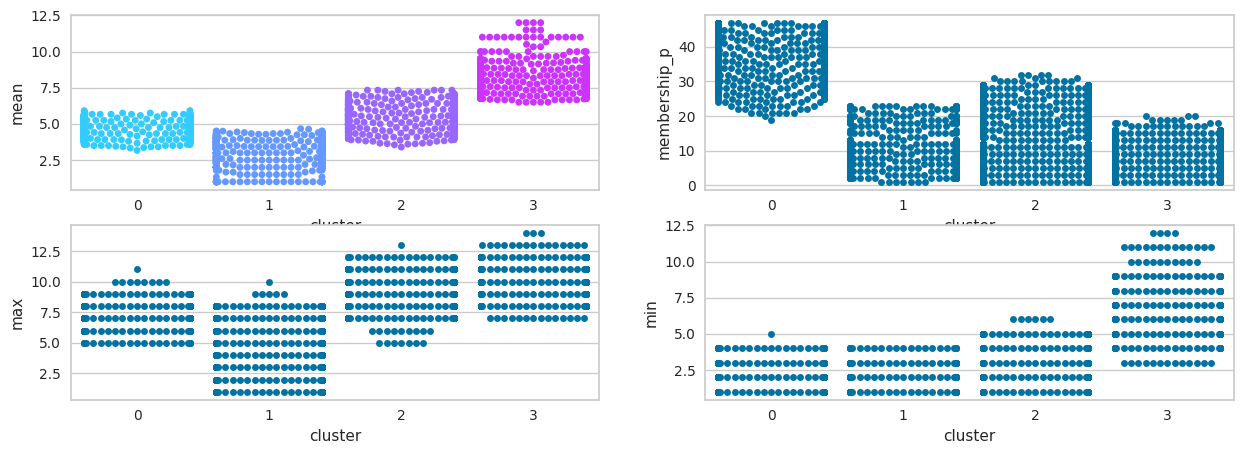

In [ ]:
fig = plt.figure(figsize=(15, 5)) # 엄청오래걸림 / skip 5분걸림
ax1 = fig.add_subplot(2, 2, 1)
ax2 = fig.add_subplot(2, 2, 2)
ax3 = fig.add_subplot(2, 2, 3)
ax4 = fig.add_subplot(2, 2, 4)

sns.swarmplot(x="cluster", y="mean", data=df,  ax=ax1, palette='cool')
sns.swarmplot(x="cluster", y="membership_p", data=df, ax=ax2)
sns.swarmplot(x="cluster", y="max", data=df, ax=ax3)
sns.swarmplot(x="cluster", y="min", data=df, ax=ax4)

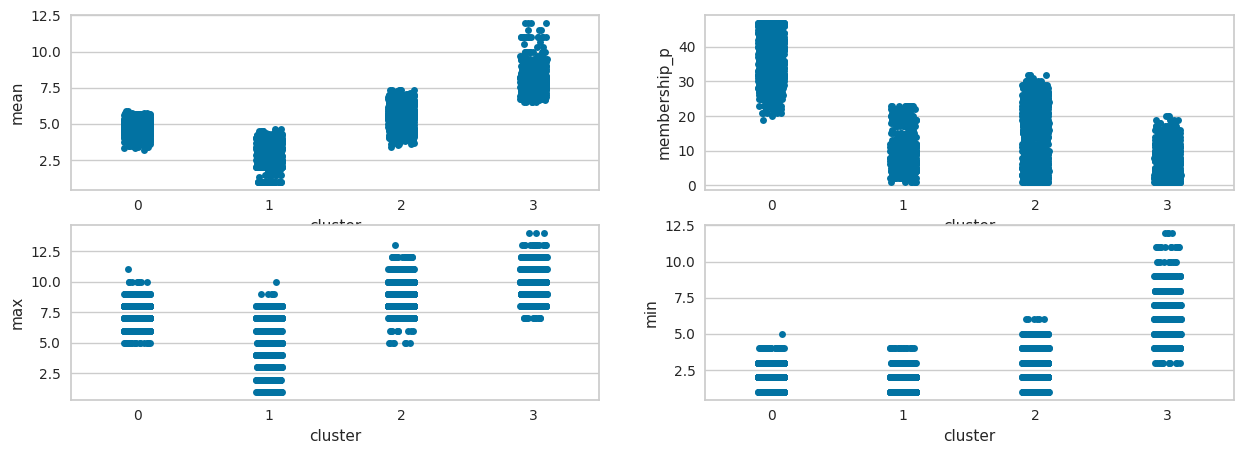

In [ ]:
# 위의 코드 수정, 계속 도는 이유 = swarmplot이 느려서 / 해결 = stripplot으로 바꾸기
import matplotlib.pyplot as plt
import seaborn as sns

# 폰트 설정
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

fig = plt.figure(figsize=(15, 5))

ax1 = fig.add_subplot(2, 2, 1)
ax2 = fig.add_subplot(2, 2, 2)
ax3 = fig.add_subplot(2, 2, 3)
ax4 = fig.add_subplot(2, 2, 4)

sns.stripplot(x="cluster", y="mean", data=df, ax=ax1)
sns.stripplot(x="cluster", y="membership_p", data=df, ax=ax2)
sns.stripplot(x="cluster", y="max", data=df, ax=ax3)
sns.stripplot(x="cluster", y="min", data=df, ax=ax4)

plt.show()

In [ ]:
df.columns = ["월평균값","월중앙값", "월최대값", "월최소값","회원기간", "cluster"]
df

# 회원기간 = 한 가지 특징, 클러스터 = 전체 특징 묶음 : 회원기간만 보지 말고 전체 평균으로 해석
# 클러스트는 회원기간, 이용횟수, 최대값 / 최소값
# 회원기간 :  오래 vs 신규/ 월평균값 : 자주 이용 / 최대값: 최고 이용 패턴

,월평균값,월중앙값,월최대값,월최소값,회원기간,cluster
0,4.833333,5.0,8,2,47,0
1,5.083333,5.0,7,3,47,0
2,4.583333,5.0,6,3,47,0
3,4.833333,4.5,7,2,47,0
4,3.916667,4.0,6,1,47,0
...,...,...,...,...,...,...
4187,8.000000,8.0,8,8,1,3
4188,10.000000,10.0,10,10,1,3
4189,8.000000,8.0,8,8,1,3
4190,11.000000,11.0,11,11,1,3


## groupby / agg
- `groupby()`는 같은 기준끼리 데이터를 묶는 기능이다.
- 예: 반별, 성별, 고객별, 월별로 묶기
- `agg()`는 묶은 데이터에 평균·합계·개수·최댓값 등을 한 번에 계산할 때 사용한다.
- 실무 데이터 분석에서는 **'묶고 → 요약하기'**가 매우 자주 사용된다.


In [ ]:
# [수업 포인트] 같은 기준의 데이터를 그룹으로 묶어서 요약
df.groupby("cluster").count()

,월평균값,월중앙값,월최대값,월최소값,회원기간
cluster,,,,,
0,1249,1249,1249,1249,1249
1,771,771,771,771,771
2,1334,1334,1334,1334,1334
3,838,838,838,838,838


| cluster | 해석               |
| ------- | ---------------- |
| 0       | 오래 다니고 꾸준한 고객    |
| 1       | 짧게 다니고 자주 안오는 고객 |
| 2       | 가끔 폭발적으로 이용      |
| 3       | 거의 안오는 고객        |

##### 이걸 알아야 마케팅, 이탈 예측, 추천 시스템
##### 클러스터가 어떤 사람들인지 파악하려고 여러 지표를 그래프로 비교하는 것

##### 중요: KMeans는 그룹만 나눠줌,의미 해석은 사람이 해야함,그래서 그래프 보는 것
